In [1]:
from anemone.experiment import *

In [73]:
class ForwardLaplace:
    def __init__(self, source, receiver, times, waveform=None, filterfunc=None, t_gatewidth=None, tolerance=None):
        self.source = source
        self.receiver = receiver
        self.times = times if isinstance(times, torch.Tensor) else torch.tensor(times)
        self.rmin = self.source.min_horizontal_distance(self.receiver).to(times.device)
        self.rmax = self.source.max_horizontal_distance(self.receiver).to(times.device)
        self.srcz = torch.tensor([source.z[0]], dtype=torch.float64)
        self.rz = self.receiver.z
        self.pfield_dz = torch.abs(self.srcz-self.rz)
        self.sfield_dz = torch.abs(self.srcz)+torch.abs(self.rz)

        self.waveform = waveform
        if t_gatewidth is not None:
            if isinstance(t_gatewidth, float): t_gatewidth = torch.ones_like(self.times)*t_gatewidth
            elif not isinstance(t_gatewidth, torch.Tensor) and t_gatewidth is not None: t_gatewidth = torch.tensor(t_gatewidth, device=self.times.device)
            self.t_gatewidth = t_gatewidth
            self.t_st = self.times-t_gatewidth/2
            self.t_end= self.times+t_gatewidth/2
        else:
            self.t_gatewidth=None
        if self.t_gatewidth is not None:
            self.tmin = (self.times-t_gatewidth/2).min()/1.1
            self.tmax = (self.times+t_gatewidth/2).max()
        else:
            self.tmin = self.times.min()
            self.tmax = self.times.max()

        self.filterfunc = filterfunc
        self.device = times.device
        if waveform is not None:
            self.tmin += -self.waveform.time.max()
            self.tmax += -self.waveform.time.min()
            waveform.time = waveform.time.to(self.device)
            waveform.amplitude = waveform.amplitude.to(self.device)
            waveform.d2wdt2 = waveform.d2wdt2.to(self.device)
            self.t_eval = torch.logspace(torch.log10(self.tmin), torch.log10(self.tmax), int(10*np.log10(self.tmax/self.tmin)), dtype=torch.double)

        else:
            self.t_eval = self.times
        self.tolerance=tolerance
        print('tmin, tmax:\t', self.t_eval.min(), self.t_eval.max(), len(self.t_eval))


    def forward(self):
        def wvlngth_integrand(wave_length):
            lmb = wave_length[None, :, None]
            def s_integrand(s):
                """ Hz from horizontal electric dipole. """
                omega = -1j*s
                tmp_u0 = u0(omega, lmb)
                intg = torch.exp(-tmp_u0*self.pfield_dz)+rte(self.sigma, self.thick, omega, lmb)*torch.exp(-tmp_u0*self.sfield_dz)
                intg *= lmb**2 / tmp_u0
            
                if self.filterfunc is not None:
                    intg *= self.filterfunc.omega_filter(omega)
                if self.waveform is not None:
                    intg /= -1j*omega.squeeze()                    
                return torch.squeeze(intg/c.fourpi).real
            cbft = invLaplace(s_integrand, n_coefficients=16, device=self.device)
            return cbft(self.t_eval)

        hkl1 = Hankel(wvlngth_integrand, 1, range=(self.rmin, self.rmax), device=self.device, tolerance=self.tolerance)
        res = integrate_around_loop(self.source, self.receiver, hkl1)
        cbft=CubicSpline(self.t_eval, res, transform=torch.log10)

        if self.t_gatewidth is None:
            t = self.times

        if self.waveform is not None:
            t_eval = t[:, None] - self.waveform.time[None, :]
            tshp = t_eval.shape
            t_eval = t_eval.reshape(-1)

            resp_step = cbft(t_eval).real.reshape(tshp)
            dbdt = resp_step @ self.waveform.d2wdt2
            if self.t_gatewidth is not None:
                cbft = CubicSpline(t, dbdt, transform=torch.log10)
            else:
                return dbdt
        if self.t_gatewidth is not None:
            return cbft.integrate(self.t_st, self.t_end, normalize=True)
        else:
            return cbft(self.times)

    def __call__(self, sigma, thickness):
        if isinstance(sigma, np.ndarray): sigma = torch.from_numpy(sigma)
        if isinstance(thickness, np.ndarray): thickness = torch.from_numpy(thickness)
        self.sigma = (sigma     + 0j).to(self.device)[...,None,None]
        self.thick = (thickness + 0j).to(self.device)[...,None,None]
        return self.forward().real*c.mu0

\\bubi4.uni.au.dk\people\matt.griffiths\_git\anemone\src\anemone\experiment\experiment.py:109: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return tc.tensor(overall_min)


tmin, tmax:	 tensor(6.8500e-06, dtype=torch.float64) tensor(0.0018, dtype=torch.float64) 24


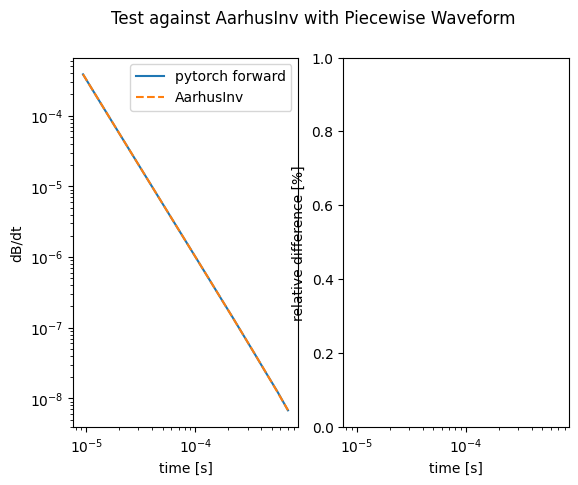

In [74]:
import torch
ainv_dbdt = torch.tensor([3.853627e-04, 2.309149e-04, 1.255715e-04, 7.168451e-05,
    4.196206e-05, 2.297534e-05, 1.302996e-05, 7.591422e-06,
    4.179841e-06, 2.394241e-06, 1.452859e-06, 8.455657e-07,
    4.466630e-07, 2.468966e-07, 1.423754e-07, 7.665493e-08,
    4.189503e-08, 2.367454e-08, 1.263738e-08, 6.809730e-09], dtype=torch.float64)

times = torch.tensor([9.350e-06, 1.145e-05, 1.458e-05, 1.822e-05, 2.255e-05, 2.867e-05, 3.595e-05, 4.460e-05, 5.660e-05, 7.070e-05, 8.630e-05, 1.071e-04,
    1.381e-04, 1.748e-04, 2.174e-04, 2.775e-04, 3.515e-04, 4.385e-04,
    5.575e-04, 7.035e-04], dtype=torch.float64)

t = torch.tensor([-1.0526e-03, -9.2963e-04,  0.0000e+00,  2.5000e-06], dtype=torch.float64)
wv = torch.tensor([0, 1, 1, 0], dtype=torch.float64)

waveform = Waveform(t, wv)


lp = Loop.square(40)
rx = Receiver()

rho = 40
sigma = 1/torch.tensor([rho,rho], dtype=torch.float64)
thick = torch.tensor([10], dtype=torch.float64)

fwr = ForwardLaplace(lp, rx, times, waveform=waveform)
dbdt = fwr(sigma, thick)

import matplotlib.pyplot as plt
fig,ax = plt.subplots(1,2, sharex=True)
ax[0].loglog(fwr.times.numpy(), np.abs(dbdt.real), label='pytorch forward')
ax[0].loglog(times,      ainv_dbdt, '--', label='AarhusInv')
ax[0].set_ylabel('dB/dt')
ax[0].legend()
# ax[0].set_aspect('equal')

# ax[1].semilogx(times, 100*np.abs(dbdt.real-ainv_dbdt)/np.abs(ainv_dbdt))
ax[1].set_ylabel('relative difference [%]')
for ax_ in ax:
    ax_.set_xlabel('time [s]')

fig.suptitle('Test against AarhusInv with Piecewise Waveform');

Why are these first few gates performing so poorly? My guess is that is has to do with the time domain convolution.

<StemContainer object of 3 artists>

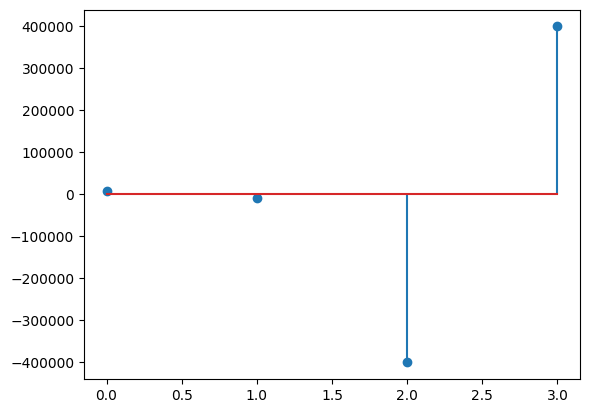

In [75]:
plt.stem(waveform.d2wdt2)

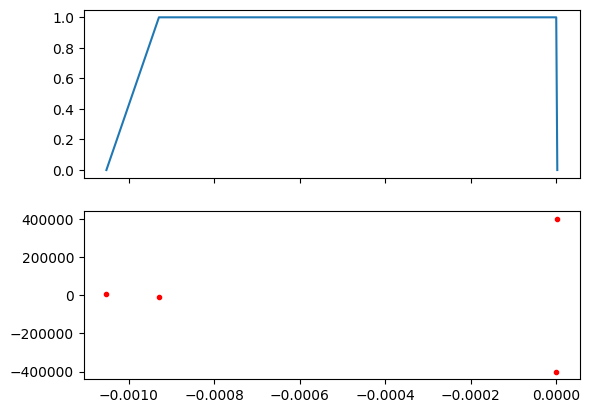

In [76]:
fig,axs = plt.subplots(2,1, sharex=True)
axs[0].plot(waveform.time, waveform.amplitude)
axs[1].plot(waveform.time, waveform.d2wdt2, 'r.')

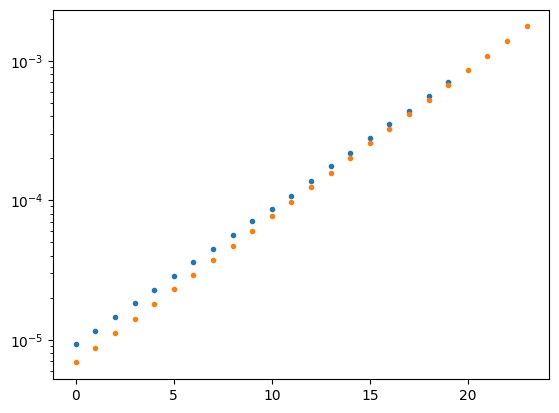

In [77]:
plt.figure()
plt.semilogy(fwr.times, '.')
plt.semilogy(fwr.t_eval, '.')